# 2. Decision Tree

CART tree: at every node it tries every feature and threshold and keeps the split with the largest drop in
Gini impurity; a leaf predicts the share of defaulters in it. Depth 6, at least 20 borrowers per leaf.

From-scratch code: `ClassificationAlgorithms/DecisionTree.py` · charts: `Images/Classification/02_Decision_Tree/` · tables: `Results/Classification/02_Decision_Tree/`

## 1. Setup and data

In [1]:
# Setup: imports, data and the fixed 60/20/20 train/validation/test split (seed 42)
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Common")))

import numpy as np
from project import SEED, Outputs, classification_data
from metrics_classification import roc_auc
from model_zoo import check_settings
from report_classification import report_classifier, sklearn_check
from DecisionTree import DecisionTreeClassifierScratch
from sklearn.tree import DecisionTreeClassifier

out = Outputs("Classification", "02_Decision_Tree")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters


## 2. Model

In [2]:
# Model: build the from-scratch model and train it
model = DecisionTreeClassifierScratch(max_depth=6, min_samples_leaf=20, random_state=SEED)
check_settings("Decision Tree", model)
model.fit(d.X_tr, d.y_tr, feature_names=d.feature_cols)
p_te = model.predict_proba(d.X_te)[:, 1]

# verification: scikit-learn's tree with the same settings should give identical predictions
sk = DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=SEED).fit(d.X_tr, d.y_tr)
same = float(np.mean(sk.predict(d.X_te) == model.predict(d.X_te)))
check = sklearn_check(
    "Decision Tree vs sklearn DecisionTreeClassifier (identical predictions)",
    1.0 - same,
    roc_auc(d.y_te, p_te),
    roc_auc(d.y_te, sk.predict_proba(d.X_te)[:, 1]),
    "1 - share identical",
)

settings match Common/model_zoo.py (10 values checked)


## 3. Results

                                  test set  at plain 0.5
threshold (chosen on validation)    0.1573        0.5000
log loss                            0.5198           NaN
accuracy                            0.2996        0.7844
precision                           0.1741        0.2750
recall / sensitivity                0.9082        0.2164
specificity                         0.1844           NaN
F1                                  0.2922        0.2422
ROC-AUC                             0.6325           NaN
PR-AUC                              0.2314           NaN
defaulters missed (FN)             28.0000           NaN

catches 90.8% of the 305 test defaulters (28 missed), flags 83.0% of applicants


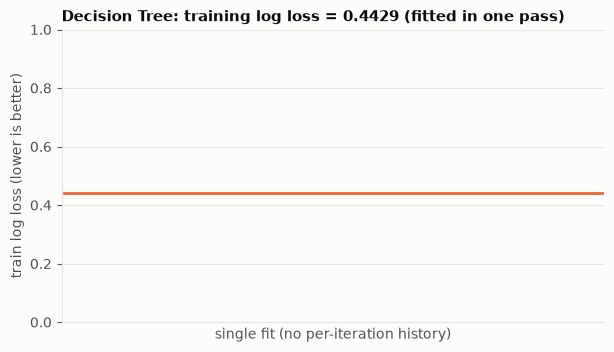

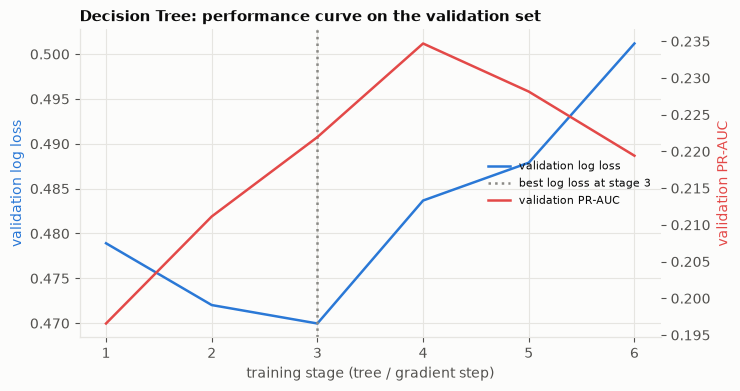

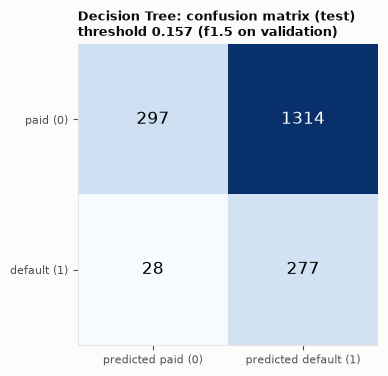

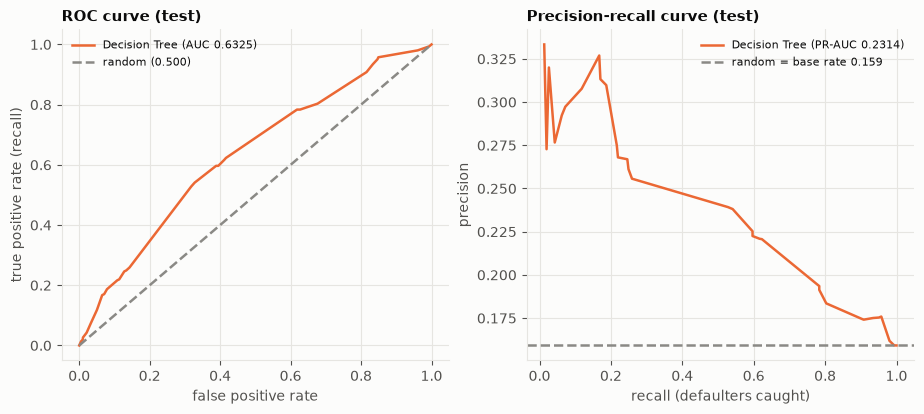

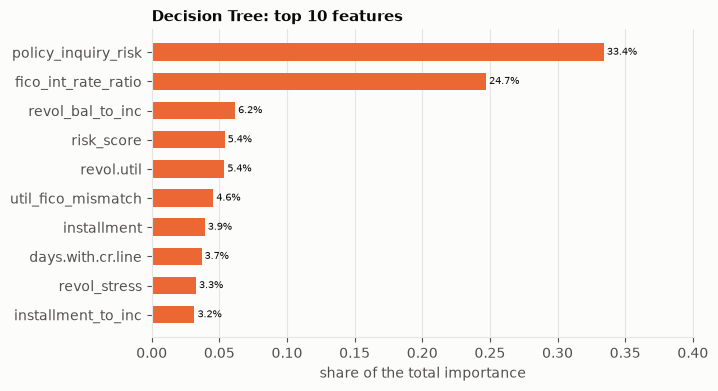


scratch vs library:
  Decision Tree vs sklearn DecisionTreeClassifier (identical predictions)
    AUC scratch 0.6325 | AUC library 0.6351 | 1 - share identical = 0.119

saved + reloaded TrainedModels/Classification/02_Decision_Tree.joblib (identical predictions: True)


In [3]:
# Results: metrics at the validation-chosen threshold, charts, scratch-vs-library check, saved model
row = report_classifier(out, "Decision Tree", model, d, check)